# Projected changes of extreme precipitation

In this tutorial, we explore how **extreme precipitation** might change in the future for the Molise region in Italy (NUTS2 region ITF2). This tutorial thus focuses on the **hazard** and how it changes under climate change scenarios.

```{admonition} Learning Objectives
:class: tip
By the end of this tutorial, you will understand:
- How to analyze changes in extreme precipitation using the concept of return periods
- How to interpret future projections of extreme precipitation with respect to a historcial baseline
- Why multiple climate models are essential for assessing uncertainty
```

```{admonition} Prerequisites
:class: note
To run this tutorial, you need to preprocess historical and projection data for the Molise region in Italy (ITF2) first! Please go to the [How-To Guide on Projections of Precipitation](../how-to-guides/precipitation_c3satlas.ipynb) to download and process precipitation projections from the CDS before running this tutorial. 
```

```{admonition} Attention
:class: caution
You will have to follow the steps in the [How-To Guide on Projections of Precipitation](../how-to-guides/precipitation_c3satlas.ipynb) first, before running this tutorial.
```

## Setup

In [1]:
import pandas as pd
#import matplotlib.pyplot as plt
#import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.stats import genextreme
import numpy as np
import os
from pathlib import Path
import geopandas as gpd

#plt.rcParams['figure.figsize'] = (12, 6)
#plt.rcParams['font.size'] = 11


## Settings

The cell below defines all parameters and file paths used throughout this tutorial. Modify `admin_id` and the data paths to apply the analysis to a different NUTS2 region.

In [2]:
# Configuration
admin_id = 'ITF2'

# Reference period for baseline statistics
baseline_start = 1976
baseline_end = 2005

# Sample grid point (nominal; snapped to nearest available point during data loading)
sample_lat = 41.6875
sample_lon = 14.5625

# Return periods analysed [years]
return_periods = np.array([2, 5, 10, 20, 50, 100])

# Future periods (start, end inclusive -- 30 years each)
future_periods = {
    'Near-term (2021-2050)': (2021, 2050),
    'Mid-term (2041-2070)':  (2041, 2070),
    'Long-term (2071-2100)': (2071, 2100),
}

# RCP scenarios
rcps = ['rcp_2_6', 'rcp_4_5', 'rcp_8_5']
rcp_labels  = {'rcp_2_6': 'RCP 2.6', 'rcp_4_5': 'RCP 4.5', 'rcp_8_5': 'RCP 8.5'}
rcp_colors  = {'rcp_2_6': 'steelblue', 'rcp_4_5': 'darkorange', 'rcp_8_5': 'crimson'}

# Paths
main_dir = Path("../")
data_dir = main_dir / 'data' / admin_id / 'extreme_precip_exposure'

hist_file = data_dir / f'{admin_id}_precip_hist_amax_all_points.csv'
proj_file = data_dir / f'{admin_id}_precip_proj_amax_all_points.csv'

print(f"Region: {admin_id} (Molise, Italy)")
print(f"Historical data : {hist_file}")
print(f"Projection data : {proj_file}")

if not hist_file.exists() or not proj_file.exists():
    print(f"\nPreprocessed data not available! \nPlease go to the How-To Guide on Projections of Precipitation (../how-to-guides/precipitation_c3satlas.ipynb) to download and process the data first.")


Region: ITF2 (Molise, Italy)
Historical data : ../data/ITF2/extreme_precip_exposure/ITF2_precip_hist_amax_all_points.csv
Projection data : ../data/ITF2/extreme_precip_exposure/ITF2_precip_proj_amax_all_points.csv


## Historical extreme precipitation as a baseline

Before we can assess future changes, we need a robust **historical baseline**. We use the period 1976–2005 as our reference — long enough (30 years) to reliably fit a statistical model, yet recent enough to represent the pre-warming climate state. The baseline is built in three steps: loading the annual maxima, fitting a GEV distribution at each model–grid-point combination, and converting the fitted parameters into return levels that serve as our event thresholds.

We begin by loading the **historical annual maxima** of daily precipitation for the full model ensemble and all grid points in the region.


In [3]:
# Load historical annual maxima (all models, all grid points)
hist_df = pd.read_csv(hist_file)
hist_df = hist_df.dropna(subset=['rx1day'])
hist_df = hist_df.drop_duplicates(subset=['member_id', 'lat', 'lon', 'year'])

n_models  = hist_df['member_id'].nunique()
n_points  = hist_df[['lat', 'lon']].drop_duplicates().shape[0]
year_min  = hist_df['year'].min()
year_max  = hist_df['year'].max()

print(f"Historical annual maxima (rx1day):")
print(f"  Models      : {n_models}")
print(f"  Grid points : {n_points}")
print(f"  Period      : {year_min}-{year_max}")
print(f"  Baseline    : {baseline_start}-{baseline_end} ({baseline_end - baseline_start + 1} years per model-point)")

# Snap sample point to nearest available grid point
all_points = hist_df[['lat', 'lon']].drop_duplicates()
dist = ((all_points['lat'] - sample_lat)**2 + (all_points['lon'] - sample_lon)**2)**0.5
nearest = all_points.loc[dist.idxmin()]
sample_lat = float(nearest['lat'])
sample_lon = float(nearest['lon'])
print(f"\nSample grid point: lat={sample_lat}, lon={sample_lon}")

# Compute region centre for map layout
lat_center = hist_df['lat'].mean()
lon_center = hist_df['lon'].mean()
geo_settings = dict(
    scope='europe',
    lonaxis_range=[lon_center - 2.5, lon_center + 2.5],
    lataxis_range=[lat_center - 1.5, lat_center + 1.5],
    showland=True, landcolor='#f5f5f0',
    showcoastlines=True, coastlinecolor='grey',
    showframe=False,
    projection_type='mercator',
)

# Load NUTS2 region boundary (Molise / ITF2)
nuts_shp = main_dir / 'data' / 'regions' / 'NUTS_RG_20M_2024_4326' / 'NUTS_RG_20M_2024_4326.shp'
nuts_gdf = gpd.read_file(nuts_shp)
sel_gdf  = nuts_gdf[nuts_gdf['NUTS_ID'] == admin_id]
print(f"\nRegion boundary loaded: {sel_gdf['NUTS_NAME'].values[0]} ({admin_id})")

def _ring_coords(polygon):
    """Return (lats, lons) lists for one polygon ring, closed, with a None separator."""
    xs, ys = polygon.exterior.xy
    lons = list(xs) + [None]
    lats = list(ys) + [None]
    return lats, lons

def region_boundary_trace(geo_key='geo', color='black', width=1.5, name='Region boundary',
                           showlegend=False):
    """Return a Scattergeo trace drawing the ITF2 region boundary."""
    all_lats, all_lons = [], []
    geom = sel_gdf.geometry.iloc[0]
    parts = list(geom.geoms) if geom.geom_type == 'MultiPolygon' else [geom]
    for part in parts:
        lats, lons = _ring_coords(part)
        all_lats.extend(lats)
        all_lons.extend(lons)
    return go.Scattergeo(
        lat=all_lats,
        lon=all_lons,
        mode='lines',
        line=dict(color=color, width=width),
        name=name,
        showlegend=showlegend,
        hoverinfo='skip',
        geo=geo_key,
    )


Historical annual maxima (rx1day):
  Models      : 71
  Grid points : 32
  Period      : 1970-2005
  Baseline    : 1976-2005 (30 years per model-point)

Sample grid point: lat=41.6875, lon=14.5625

Region boundary loaded: Molise (ITF2)


### Fit GEV distribution

We fit a Generalised Extreme Value (GEV) distribution to the annual maxima at each grid point and for each ensemble member, using the baseline period as the reference. The three GEV parameters are:

- **Shape (xi):** governs the tail behaviour (positive = heavy tail, negative = bounded upper tail, zero = Gumbel)
- **Location (mu):** shifts the distribution, closely related to the median annual maximum
- **Scale (sigma):** controls the spread of the distribution


In [4]:
# Fit GEV to each (member_id, lat, lon) combo using the baseline period
baseline_df = hist_df[
    (hist_df['year'] >= baseline_start) & (hist_df['year'] <= baseline_end)
]

gev_records = []
for (member_id, lat, lon), group in baseline_df.groupby(['member_id', 'lat', 'lon']):
    amax = group['rx1day'].dropna().values
    if len(amax) < 10:
        continue
    try:
        shape, loc, scale = genextreme.fit(amax)
        gev_records.append({
            'member_id': member_id, 'lat': lat, 'lon': lon,
            'shape': shape, 'loc': loc, 'scale': scale,
        })
    except Exception:
        continue

gev_params_df = pd.DataFrame(gev_records)

n_fit        = len(gev_params_df)
n_fit_models = gev_params_df['member_id'].nunique()
n_fit_points = gev_params_df[['lat', 'lon']].drop_duplicates().shape[0]

print(f"GEV fitted for {n_fit} (model, grid point) combinations")
print(f"  Models      : {n_fit_models}")
print(f"  Grid points : {n_fit_points}")
print(f"\nGEV parameter summary (median across all model-grid combinations):")
print(f"  Shape  (xi)  : {gev_params_df['shape'].median():.3f}  "
      f"(range: {gev_params_df['shape'].min():.3f} to {gev_params_df['shape'].max():.3f})")
print(f"  Location (mu): {gev_params_df['loc'].median():.1f} mm  "
      f"(range: {gev_params_df['loc'].min():.1f} to {gev_params_df['loc'].max():.1f} mm)")
print(f"  Scale (sigma): {gev_params_df['scale'].median():.1f} mm  "
      f"(range: {gev_params_df['scale'].min():.1f} to {gev_params_df['scale'].max():.1f} mm)")

# Select an example model for the spatial maps below
example_model = gev_params_df['member_id'].iloc[0]
print(f"\nExample model for spatial maps: {example_model}")


GEV fitted for 2272 (model, grid point) combinations
  Models      : 71
  Grid points : 32

GEV parameter summary (median across all model-grid combinations):
  Shape  (xi)  : -0.122  (range: -5.070 to 5.201)
  Location (mu): 39.8 mm  (range: 18.3 to 149.2 mm)
  Scale (sigma): 12.2 mm  (range: 0.6 to 142.5 mm)

Example model for spatial maps: CCCma_CanESM2_r1i1p1_CLMcom_CCLM4-8-17_v1


The GEV parameters vary across grid points and between models. The maps below show their spatial distribution across the region for one example model.


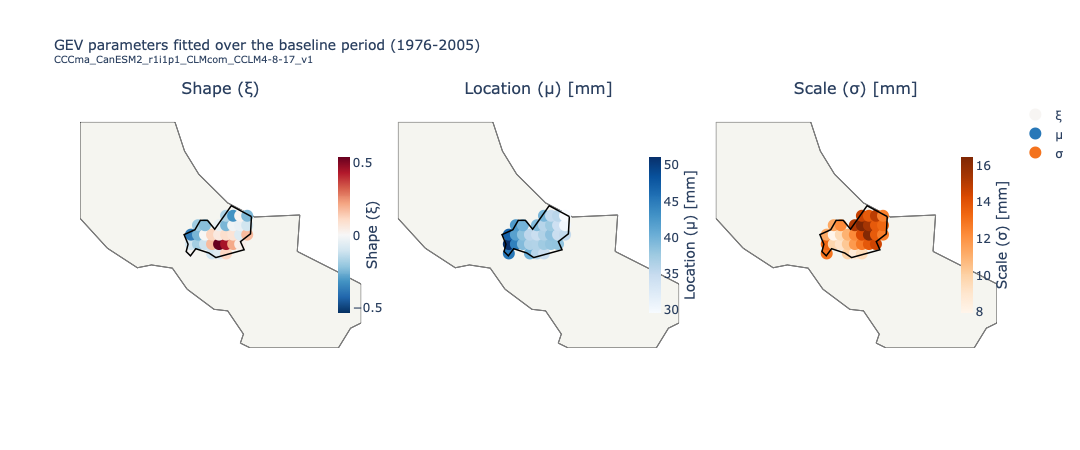

In [5]:
# 1x3 spatial maps of GEV parameters for the example model
model_gev = gev_params_df[gev_params_df['member_id'] == example_model].copy()

# (column, subplot title, colorscale, legend name, center-on-zero)
params_cfg = [
    ('shape', 'Shape (\u03be)',          'RdBu_r',  '\u03be',  True),
    ('loc',   'Location (\u03bc) [mm]',  'Blues',   '\u03bc',  False),
    ('scale', 'Scale (\u03c3) [mm]',     'Oranges', '\u03c3',  False),
]

fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=[p[1] for p in params_cfg],
    specs=[[{'type': 'geo'}, {'type': 'geo'}, {'type': 'geo'}]],
    horizontal_spacing=0.04,
)

colorbar_x = [0.27, 0.61, 0.95]

for col, (col_name, label, cscale, legend_name, center_zero) in enumerate(params_cfg, start=1):
    vals    = model_gev[col_name]
    geo_key = 'geo' if col == 1 else f'geo{col}'

    if center_zero:
        abs_max = max(abs(vals.min()), abs(vals.max()))
        cmin, cmax = -abs_max, abs_max
    else:
        cmin, cmax = vals.min(), vals.max()

    fig.add_trace(
        go.Scattergeo(
            lat=model_gev['lat'],
            lon=model_gev['lon'],
            mode='markers',
            name=legend_name,
            marker=dict(
                color=vals,
                colorscale=cscale,
                size=12,
                showscale=True,
                colorbar=dict(
                    title=dict(text=label, side='right'),
                    thickness=12,
                    x=colorbar_x[col - 1],
                    len=0.65,
                    lenmode='fraction',
                    thicknessmode='pixels',
                ),
                cmin=cmin,
                cmax=cmax,
            ),
            hovertemplate=(
                f'lat: %{{lat:.4f}}, lon: %{{lon:.4f}}<br>'
                f'{col_name}: %{{marker.color:.3f}}<extra></extra>'
            ),
            geo=geo_key,
        ),
        row=1, col=col,
    )
    fig.add_trace(region_boundary_trace(geo_key=geo_key), row=1, col=col)
    fig.update_layout(**{geo_key: geo_settings})

fig.update_layout(
    title=dict(
        text=(
            f'GEV parameters fitted over the baseline period ({baseline_start}-{baseline_end})'
            f'<br><sup>{example_model}</sup>'
        ),
        font=dict(size=14),
    ),
    autosize=True,
    height=450,
)
fig.show(config={'displayModeBar': True, 'responsive': True})


The **location (μ)** broadly follows orography and coastal proximity — foothills of the Apennines tend to show higher annual maxima than coastal lowlands. The **scale (σ)** reflects how much the annual maximum varies from year to year; larger values indicate more unpredictable extremes. The **shape (ξ)** is close to zero across most of the region, consistent with a near-Gumbel tail; slightly positive values at some grid points suggest a heavier upper tail and a non-negligible probability of truly exceptional events.

### Historical return levels

Using the fitted GEV parameters, we derive the return level $x_T$ for each return period $T$ at every model-grid point combination:

$$x_T = F^{-1}\!\left(1 - \frac{1}{T}\right)$$

where $F^{-1}$ is the inverse of the fitted GEV cumulative distribution function.


In [6]:
# Compute return levels for all (member_id, lat, lon) and all return periods
return_levels_records = []
for _, row in gev_params_df.iterrows():
    for rp in return_periods:
        rl = float(genextreme.ppf(1 - 1 / rp, row['shape'], row['loc'], row['scale']))
        # count occurrences of this return level in the historical data for context
        rc = hist_df[
            (hist_df['member_id'] == row['member_id']) &
            (hist_df['lat'] == row['lat']) &
            (hist_df['lon'] == row['lon']) &
            (hist_df['rx1day'] >= rl)
        ].shape[0]
        return_levels_records.append({
            'member_id':    row['member_id'],
            'lat':          row['lat'],
            'lon':          row['lon'],
            'return_period': rp,
            'return_level':  rl,
            'return_count':  rc,
        })

return_levels_df = pd.DataFrame(return_levels_records)

# Print summary at the sample grid point
sample_rl = return_levels_df[
    (return_levels_df['lat'] == sample_lat) &
    (return_levels_df['lon'] == sample_lon)
]

print(f"Return levels at the sample grid point (lat={sample_lat}, lon={sample_lon}):")
print(f"  (median and multi-model range across {sample_rl['member_id'].nunique()} ensemble members)")
print(f"\n{'Return period':>16} | {'Median':>10} | {'Min':>10} | {'Max':>10} | {'Occurrences':>10}")
print("-" * 55)
for rp in return_periods:
    rp_vals = sample_rl[sample_rl['return_period'] == rp]['return_level']
    rp_counts = sample_rl[sample_rl['return_period'] == rp]['return_count']
    print(f"{rp:>13}-year | {rp_vals.median():>8.1f} mm | {rp_vals.min():>8.1f} mm | {rp_vals.max():>8.1f} mm | {rp_counts.sum():>8} occurrences")


Return levels at the sample grid point (lat=41.6875, lon=14.5625):
  (median and multi-model range across 71 ensemble members)

   Return period |     Median |        Min |        Max | Occurrences
-------------------------------------------------------
            2-year |     37.5 mm |     23.9 mm |     63.9 mm |     1256 occurrences
            5-year |     49.0 mm |     30.4 mm |     93.6 mm |      497 occurrences
           10-year |     58.3 mm |     34.5 mm |    119.9 mm |      281 occurrences
           20-year |     69.6 mm |     38.5 mm |    151.5 mm |      137 occurrences
           50-year |     82.8 mm |     43.7 mm |    204.3 mm |       44 occurrences
          100-year |     94.7 mm |     47.7 mm |    255.3 mm |       21 occurrences


#### Spatial variability

The intensity of a given return period event varies considerably across the region, reflecting differences in orography, proximity to the sea, and local storm dynamics.


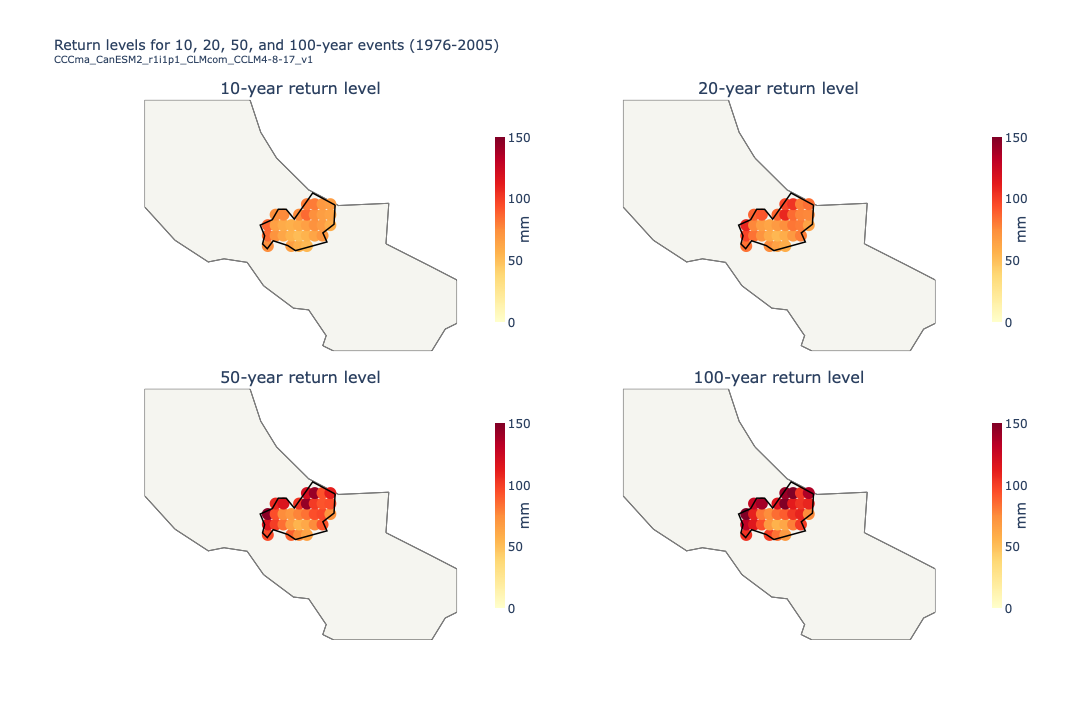

In [19]:
# 2x2 maps of 10, 20, 50, 100-year return levels for the example model
rp_subset   = [10, 20, 50, 100]
model_rl    = return_levels_df[return_levels_df['member_id'] == example_model]

specs_2x2 = [[{'type': 'geo'}, {'type': 'geo'}],
             [{'type': 'geo'}, {'type': 'geo'}]]

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=[f'{rp}-year return level' for rp in rp_subset],
    specs=specs_2x2,
    vertical_spacing=0.07,
    horizontal_spacing=0.04,
)

# (colorbar-x, colorbar-y-anchor)
cb_cfg = [(0.44, 0.95), (0.98, 0.95), (0.44, 0.42), (0.98, 0.42)]

for idx, rp_val in enumerate(rp_subset):
    row = idx // 2 + 1
    col = idx %  2 + 1
    geo_key  = 'geo' if idx == 0 else f'geo{idx + 1}'
    rp_data  = model_rl[model_rl['return_period'] == rp_val]
    cb_x, cb_y = cb_cfg[idx]

    fig.add_trace(
        go.Scattergeo(
            lat=rp_data['lat'],
            lon=rp_data['lon'],
            mode='markers',
            name=f'{rp_val}-year',
            showlegend=False,
            marker=dict(
                color=rp_data['return_level'],
                colorscale='YlOrRd',
                size=12,
                showscale=True,
                cmin=0,#rp_data['return_level'].min(),
                cmax=150,#rp_data['return_level'].max(),
                colorbar=dict(
                    title=dict(text='mm', side='right'),
                    thickness=10,
                    x=cb_x, y=cb_y,
                    len=0.38,
                    lenmode='fraction',
                    thicknessmode='pixels',
                    yanchor='top',
                ),
            ),
            hovertemplate=(
                f'{rp_val}-yr return level<br>'
                'lat: %{lat:.4f}, lon: %{lon:.4f}<br>'
                '%{marker.color:.1f} mm<extra></extra>'
            ),
            geo=geo_key,
        ),
        row=row, col=col,
    )
    fig.add_trace(region_boundary_trace(geo_key=geo_key), row=row, col=col)
    fig.update_layout(**{geo_key: geo_settings})

fig.update_layout(
    title=dict(
        text=(
            f'Return levels for 10, 20, 50, and 100-year events '
            f'({baseline_start}-{baseline_end})'
            f'<br><sup>{example_model}</sup>'
        ),
        font=dict(size=14),
    ),
    autosize=True,
    height=720,
)
fig.show(config={'displayModeBar': True, 'responsive': True})


The figure shows the precipitation in mm associated with return periods of 10, 20, 50, and 100 years. 

#### Spatial and multi-model uncertainty

The return level estimate is subject to two main sources of uncertainty: the variability across grid points within the region (spatial uncertainty), and the spread across ensemble members at a single location (model uncertainty). The plot below shows both uncertainty ranges together with their respective medians.


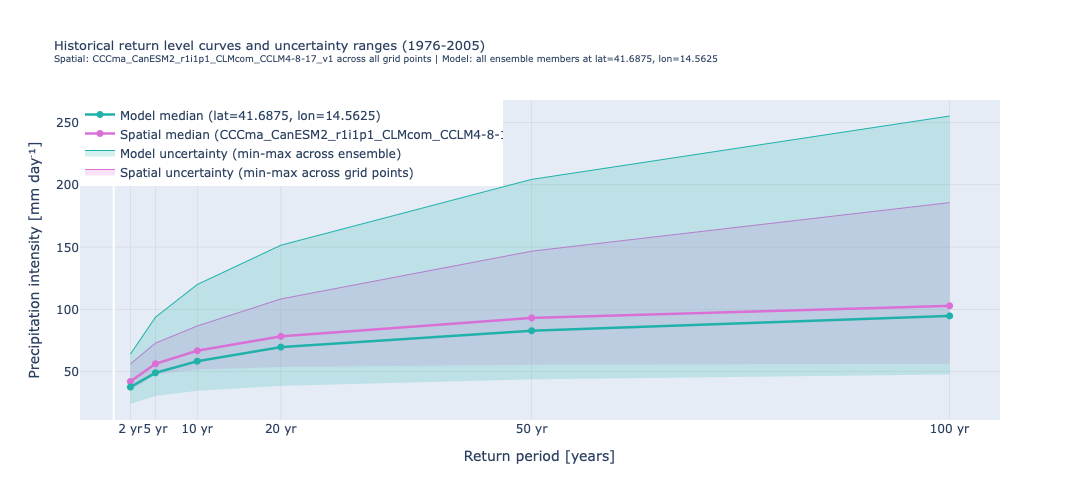

In [20]:
# ---- Spatial uncertainty: all grid points for the example model ----
spatial_rl = return_levels_df[return_levels_df['member_id'] == example_model]
spatial_pivot = spatial_rl.pivot_table(
    index=['lat', 'lon'], columns='return_period', values='return_level'
)
sp_min = spatial_pivot.min(axis=0).values
sp_max = spatial_pivot.max(axis=0).values
sp_med = spatial_pivot.median(axis=0).values

# ---- Model uncertainty: all ensemble members at the sample grid point ----
model_rl_pt = return_levels_df[
    (return_levels_df['lat'] == sample_lat) &
    (return_levels_df['lon'] == sample_lon)
]
model_pivot = model_rl_pt.pivot_table(
    index='member_id', columns='return_period', values='return_level'
)
mo_min = model_pivot.min(axis=0).values
mo_max = model_pivot.max(axis=0).values
mo_med = model_pivot.median(axis=0).values

fig = go.Figure()

# Spatial uncertainty band
fig.add_trace(go.Scatter(
    x=return_periods, y=sp_min,
    mode='lines', line=dict(color='rgba(218,112,214,0)', width=0),
    showlegend=False, hoverinfo='skip',
))
fig.add_trace(go.Scatter(
    x=return_periods, y=sp_max,
    mode='lines', line=dict(color='orchid', width=1),
    fill='tonexty', fillcolor='rgba(218,112,214,0.2)',
    name='Spatial uncertainty (min-max across grid points)',
    hovertemplate='Spatial max: %{y:.1f} mm<extra></extra>',
))

# Model uncertainty band
fig.add_trace(go.Scatter(
    x=return_periods, y=mo_min,
    mode='lines', line=dict(color='rgba(32,178,170,0)', width=0),
    showlegend=False, hoverinfo='skip',
))
fig.add_trace(go.Scatter(
    x=return_periods, y=mo_max,
    mode='lines', line=dict(color='lightseagreen', width=1),
    fill='tonexty', fillcolor='rgba(32,178,170,0.2)',
    name='Model uncertainty (min-max across ensemble)',
    hovertemplate='Model max: %{y:.1f} mm<extra></extra>',
))

# Median spatial return level curve (example model)
fig.add_trace(go.Scatter(
    x=return_periods, y=sp_med,
    mode='lines+markers', line=dict(color='orchid', width=2.5),
    marker=dict(size=7),
    name=f'Spatial median ({example_model})',
    hovertemplate='%{x}-yr: %{y:.1f} mm (spatial median)<extra></extra>',
))

# Median model return level curve (sample grid point)
fig.add_trace(go.Scatter(
    x=return_periods, y=mo_med,
    mode='lines+markers', line=dict(color='lightseagreen', width=2.5),
    marker=dict(size=7),
    name=f'Model median (lat={sample_lat}, lon={sample_lon})',
    hovertemplate='%{x}-yr: %{y:.1f} mm (model median)<extra></extra>',
))

fig.update_layout(
    title=dict(
        text=(
            f'Historical return level curves and uncertainty ranges ({baseline_start}-{baseline_end})<br>'
            f'<sup>Spatial: {example_model} across all grid points | '
            f'Model: all ensemble members at lat={sample_lat}, lon={sample_lon}</sup>'
        ),
        font=dict(size=13),
    ),
    xaxis=dict(
        title='Return period [years]',
        tickmode='array',
        tickvals=return_periods.tolist(),
        ticktext=[f'{rp} yr' for rp in return_periods],
        showgrid=True, gridcolor='lightgrey', gridwidth=0.5,
    ),
    yaxis=dict(
        title='Precipitation intensity [mm day\u207b\u00b9]',
        showgrid=True, gridcolor='lightgrey', gridwidth=0.5,
    ),
    legend=dict(x=0, y=1, xanchor='left', yanchor='top'),
    autosize=True,
    height=500,
)
fig.show(config={'displayModeBar': True, 'responsive': True})


### Historical baseline

The GEV fits and derived return levels establish the historical baseline for the Molise region. The spatial spread and the multi-model spread are of comparable magnitude, both increasing with return period. The table below summarises the key statistics for the full ensemble and the entire region.


In [9]:
print("=" * 70)
print(f"HISTORICAL BASELINE ({baseline_start}-{baseline_end})")
print(f"Region: {admin_id} | Models: {n_fit_models} | Grid points: {n_fit_points}")
print("=" * 70)
print(f"\n{'Return period':>16} | {'Reg. median':>12} | {'Model spread':>14} | {'Spatial spread':>15}")
print("-" * 68)
for rp in return_periods:
    all_rl   = return_levels_df[return_levels_df['return_period'] == rp]['return_level']
    mo_rl_rp = model_rl_pt[model_rl_pt['return_period'] == rp]['return_level']
    sp_rl_rp = spatial_rl[spatial_rl['return_period'] == rp]['return_level']
    m_spread = mo_rl_rp.max() - mo_rl_rp.min()
    s_spread = sp_rl_rp.max() - sp_rl_rp.min()
    print(f"{rp:>13}-year | {all_rl.median():>10.1f} mm | {m_spread:>12.1f} mm | {s_spread:>13.1f} mm")
print("=" * 70)

print(return_levels_df.columns)

HISTORICAL BASELINE (1976-2005)
Region: ITF2 | Models: 71 | Grid points: 32

   Return period |  Reg. median |   Model spread |  Spatial spread
--------------------------------------------------------------------
            2-year |       44.4 mm |         40.0 mm |          21.7 mm
            5-year |       61.0 mm |         63.2 mm |          25.3 mm
           10-year |       72.9 mm |         85.4 mm |          35.0 mm
           20-year |       85.6 mm |        113.0 mm |          54.6 mm
           50-year |      103.4 mm |        160.6 mm |          91.2 mm
          100-year |      117.7 mm |        207.6 mm |         129.4 mm
Index(['member_id', 'lat', 'lon', 'return_period', 'return_level',
       'return_count'],
      dtype='object')


#### Number of extreme events

As a consistency check on the GEV fits, we count how many times the derived T-year threshold is actually exceeded in the historical record. For a well-calibrated fit, a T-year event should occur roughly $30/T$ times in a 30-year window — for example, about 3 exceedances for the 10-year event. Systematic over- or under-counts would indicate a poor fit.

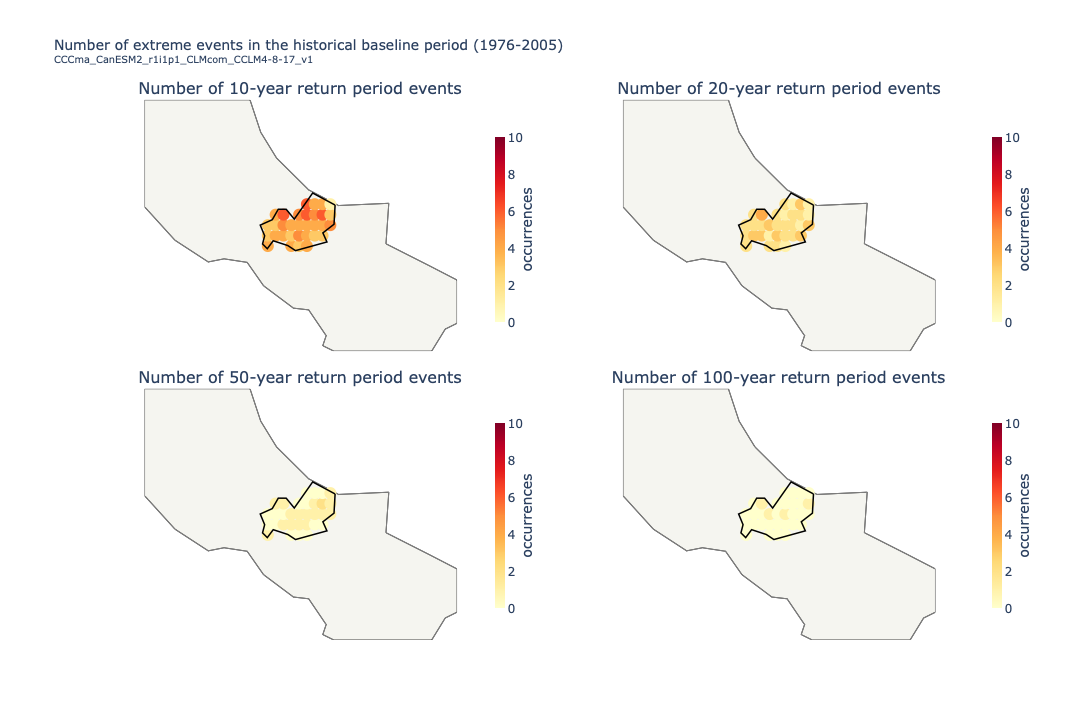

In [10]:
# 2x2 maps of 10, 20, 50, 100-year occurrences for the example model
rp_subset   = [10, 20, 50, 100]
model_rl    = return_levels_df[return_levels_df['member_id'] == example_model]

specs_2x2 = [[{'type': 'geo'}, {'type': 'geo'}],
             [{'type': 'geo'}, {'type': 'geo'}]]

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=[f'Number of {rp}-year return period events' for rp in rp_subset],
    specs=specs_2x2,
    vertical_spacing=0.07,
    horizontal_spacing=0.04,
)

# (colorbar-x, colorbar-y-anchor)
cb_cfg = [(0.44, 0.95), (0.98, 0.95), (0.44, 0.42), (0.98, 0.42)]

for idx, rp_val in enumerate(rp_subset):
    row = idx // 2 + 1
    col = idx %  2 + 1
    geo_key  = 'geo' if idx == 0 else f'geo{idx + 1}'
    rp_data  = model_rl[model_rl['return_period'] == rp_val]
    cb_x, cb_y = cb_cfg[idx]

    fig.add_trace(
        go.Scattergeo(
            lat=rp_data['lat'],
            lon=rp_data['lon'],
            mode='markers',
            name=f'{rp_val}-year',
            showlegend=False,
            marker=dict(
                color=rp_data['return_count'],
                colorscale='YlOrRd',
                size=12,
                showscale=True,
                cmin=0, #rp_data['return_count'].min(),
                cmax=10, #rp_data['return_count'].max(),
                colorbar=dict(
                    title=dict(text='occurrences', side='right'),
                    thickness=10,
                    x=cb_x, y=cb_y,
                    len=0.38,
                    lenmode='fraction',
                    thicknessmode='pixels',
                    yanchor='top',
                ),
            ),
            hovertemplate=(
                f'Number of {rp_val} events <br>'
                'lat: %{lat:.4f}, lon: %{lon:.4f}<br>'
                '%{marker.color:.1f} occurrences<extra></extra>'
            ),
            geo=geo_key,
        ),
        row=row, col=col,
    )
    fig.add_trace(region_boundary_trace(geo_key=geo_key), row=row, col=col)
    fig.update_layout(**{geo_key: geo_settings})

fig.update_layout(
    title=dict(
        text=(
            f'Number of extreme events in the historical baseline period '
            f'({baseline_start}-{baseline_end})'
            f'<br><sup>{example_model}</sup>'
        ),
        font=dict(size=14),
    ),
    autosize=True,
    height=720,
)
fig.show(config={'displayModeBar': True, 'responsive': True})


Return period: 2 years
               Model | Avg occurrences | Min occurrences | Max occurrences
----------------------------------------------------------------------
CCCma_CanESM2_r1i1p1_CLMcom_CCLM4-8-17_v1 |           17.97 |              15 |              21
CCCma_CanESM2_r1i1p1_GERICS_REMO2015_v1 |           17.22 |              15 |              22
CNRM-CERFACS_CNRM-CM5_r1i1p1_CLMcom-ETH_COSMO-crCLIM-v1-1_v1 |           17.38 |              14 |              22
CNRM-CERFACS_CNRM-CM5_r1i1p1_CLMcom_CCLM4-8-17_v1 |           17.81 |              15 |              20
CNRM-CERFACS_CNRM-CM5_r1i1p1_CNRM_ALADIN63_v2 |           18.25 |              16 |              22
CNRM-CERFACS_CNRM-CM5_r1i1p1_DMI_HIRHAM5_v2 |           17.72 |              14 |              21
CNRM-CERFACS_CNRM-CM5_r1i1p1_GERICS_REMO2015_v2 |           18.62 |              14 |              24
CNRM-CERFACS_CNRM-CM5_r1i1p1_ICTP_RegCM4-6_v1 |           18.25 |              14 |              22
CNRM-CERFACS_CNRM-CM5

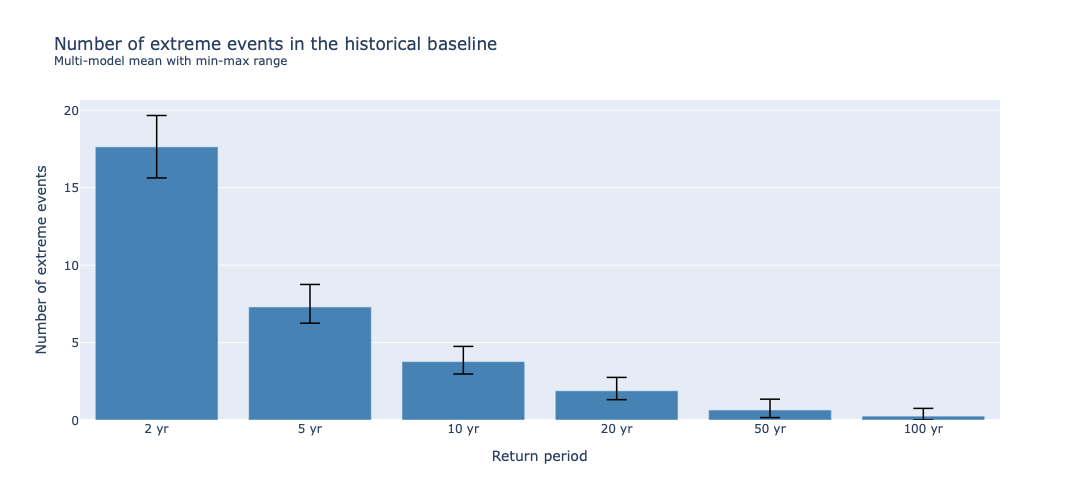

In [11]:
### Calculate average number of occurrences for each return period averaged across all grid points for each model, i.e. a n_model x n_return_periods average occurrences
for rp in return_periods:
    rp_data = return_levels_df[return_levels_df['return_period'] == rp]
    model_means = rp_data.groupby('member_id')['return_count'].mean()
    model_mins = rp_data.groupby('member_id')['return_count'].min()
    model_maxs = rp_data.groupby('member_id')['return_count'].max()
    print(f"\nReturn period: {rp} years")
    print(f"{'Model':>20} | {'Avg occurrences':>15} | {'Min occurrences':>15} | {'Max occurrences':>15}")
    print("-" * 70)
    for model in model_means.index:
        print(f"{model:>20} | {model_means[model]:>15.2f} | {model_mins[model]:>15} | {model_maxs[model]:>15}") 
    
    # save in a dataframe for later plotting
    if rp == return_periods[0]:
        occurrences_summary_df = pd.DataFrame({
            'model': model_means.index,
            'avg_occurrences': model_means.values,
            'min_occurrences': model_mins.values,
            'max_occurrences': model_maxs.values,
            'return_period': rp,
        })
    else:
        temp_df = pd.DataFrame({
            'model': model_means.index,
            'avg_occurrences': model_means.values,
            'min_occurrences': model_mins.values,
            'max_occurrences': model_maxs.values,
            'return_period': rp,
        })
        occurrences_summary_df = pd.concat([occurrences_summary_df, temp_df], ignore_index=True)    

# calculate multi-model mean and min-max range for each return period
summary_stats = occurrences_summary_df.groupby('return_period')['avg_occurrences'].agg(['mean', 'min', 'max']).reset_index()
summary_stats = summary_stats.rename(columns={'mean': 'avg_occurrences', 'min': 'min_occurrences', 'max': 'max_occurrences'})
print("\nSummary of average occurrences across models for each return period:")
print(summary_stats)

# plot a bar chart of the multi-model mean for each return period, with error bars showing the min-max range across the models
fig = go.Figure()
fig.add_trace(go.Bar(
    x=summary_stats['return_period'].astype(str) + ' yr',
    y=summary_stats['avg_occurrences'],
    name='Average occurrences (multi-model mean)',
    marker_color='steelblue',
    error_y=dict(
        type='data',
        symmetric=False,
        array=summary_stats['max_occurrences'] - summary_stats['avg_occurrences'],
        arrayminus=summary_stats['avg_occurrences'] - summary_stats['min_occurrences'],
        thickness=1.5,
        width=10,
        color='black',
    ),
))
fig.update_layout(
    title='Number of extreme events in the historical baseline <br><sup>Multi-model mean with min-max range</sup>',
    xaxis_title='Return period',
    yaxis_title='Number of extreme events',
    yaxis=dict(range=[0, summary_stats['max_occurrences'].max() + 1]),
    autosize=True,
    height=500,
)
fig.show(config={'displayModeBar': True, 'responsive': True})

The multi-model mean closely matches the theoretical expectation ($30/T$ occurrences), giving confidence that the GEV fits are reliable. The spread across models is largest for high return periods — a direct consequence of smaller sample sizes at the tails — and this model uncertainty will propagate into the future projections.

## Future changes

We now use the historical baseline return levels as event thresholds and assess how frequently these events occur in future climate projections. For each model and grid point, we count how many times the T-year historical threshold is exceeded within each 30-year future window and express the result as a change in event frequency relative to the baseline.


In [12]:
# Load projection data (all models, all grid points, all RCPs)
print("Loading projection data -- this may take a moment ...")
proj_df = pd.read_csv(proj_file)
proj_df = proj_df.dropna(subset=['rx1day'])
proj_df = proj_df.drop_duplicates(subset=['member_id', 'lat', 'lon', 'year', 'rcp'])

n_proj_models = proj_df['member_id'].nunique()
n_proj_points = proj_df[['lat', 'lon']].drop_duplicates().shape[0]
year_min_proj = proj_df['year'].min()
year_max_proj = proj_df['year'].max()

print(f"Projection annual maxima (rx1day):")
print(f"  Models      : {n_proj_models}")
print(f"  Grid points : {n_proj_points}")
print(f"  Period      : {year_min_proj}-{year_max_proj}")
print(f"  RCPs        : {sorted(proj_df['rcp'].unique())}")


Loading projection data -- this may take a moment ...
Projection annual maxima (rx1day):
  Models      : 71
  Grid points : 32
  Period      : 2006-2100
  RCPs        : ['rcp_2_6', 'rcp_4_5', 'rcp_8_5']


### Change in future number of events (using historical thresholds)

For each T-year event, if $n$ exceedances of the historical threshold occur within a 30-year future window, the effective future return period is $T_\text{fut} = 30 / n$. The likelihood change factor is then:

$$\text{factor} = \frac{T}{T_\text{fut}} = \frac{n \cdot T}{30}$$

A factor greater than 1 means the event has become more frequent; a factor less than 1 means it has become less frequent.

The three future periods are:
- **Near-term (2021-2050)**
- **Mid-term (2041-2070)** (overlaps with near-term by 10 years)
- **Long-term (2071-2100)**


In [13]:
# Threshold lookup table derived from historical return levels
threshold_df = return_levels_df.rename(columns={'return_level': 'hist_threshold', 'return_count': 'hist_count'})

# Compute future counts and exceedance likelihood factors per period, RCP, model, grid point
print("\nCalculating exceedance counts for all future periods ...")
future_records = []
for period_name, (pstart, pend) in future_periods.items():
    period_proj = proj_df[(proj_df['year'] >= pstart) & (proj_df['year'] <= pend)]
    window_len  = pend - pstart + 1  # 30 years

    for rcp in rcps:
        rcp_proj = period_proj[period_proj['rcp'] == rcp]
        if rcp_proj.empty:
            print("rcp {} has no data for period {}-{}, skipping.".format(rcp, pstart, pend))
            continue

        # Merge annual maxima with model- and point-specific historical thresholds for each of the return periods, then count exceedances per model, point, and return period
        merged = rcp_proj.merge(
            threshold_df[['member_id', 'lat', 'lon', 'return_period', 'hist_threshold', 'hist_count']],
            on=['member_id', 'lat', 'lon'],
            how='inner',
        )
        merged['exceeds'] = merged['rx1day'] >= merged['hist_threshold']

        counts = (
            merged.groupby(['member_id', 'lat', 'lon', 'return_period'])['exceeds']
            .sum()
            .reset_index(name='proj_count')
        )
        counts['period']       = period_name
        counts['rcp']          = rcp
        # factor (1 = no change, >1 = more frequent); assuming both are based on the same window length, so we can directly compare counts
        counts['factor']       = counts['proj_count'] / threshold_df['hist_count'].replace(0, np.nan)  # avoid division by zero; will result in NaN factor if no historical occurrences

        future_records.append(counts)

future_rp_df = pd.concat(future_records, ignore_index=True)
print(f"Done. {len(future_rp_df):,} rows in future_rp_df.")
print(f"  (model x grid point x RCP x return period x period combinations)")



Calculating exceedance counts for all future periods ...
Done. 67,968 rows in future_rp_df.
  (model x grid point x RCP x return period x period combinations)



Summary of exceedance likelihood factors across models for each return period and future period:
        rcp                 period  return_period  avg_factor  min_factor  \
0   rcp_2_6  Long-term (2071-2100)              2    1.018359    0.214286   
1   rcp_2_6  Long-term (2071-2100)              5    1.165260    0.125000   
2   rcp_2_6  Long-term (2071-2100)             10    1.301985    0.000000   
3   rcp_2_6  Long-term (2071-2100)             20    1.514051    0.000000   
4   rcp_2_6  Long-term (2071-2100)             50    1.257433    0.000000   
5   rcp_2_6  Long-term (2071-2100)            100    1.041922    0.000000   
6   rcp_2_6   Mid-term (2041-2070)              2    1.029774    0.142857   
7   rcp_2_6   Mid-term (2041-2070)              5    1.143786    0.000000   
8   rcp_2_6   Mid-term (2041-2070)             10    1.289233    0.000000   
9   rcp_2_6   Mid-term (2041-2070)             20    1.539473    0.000000   
10  rcp_2_6   Mid-term (2041-2070)             50    1.

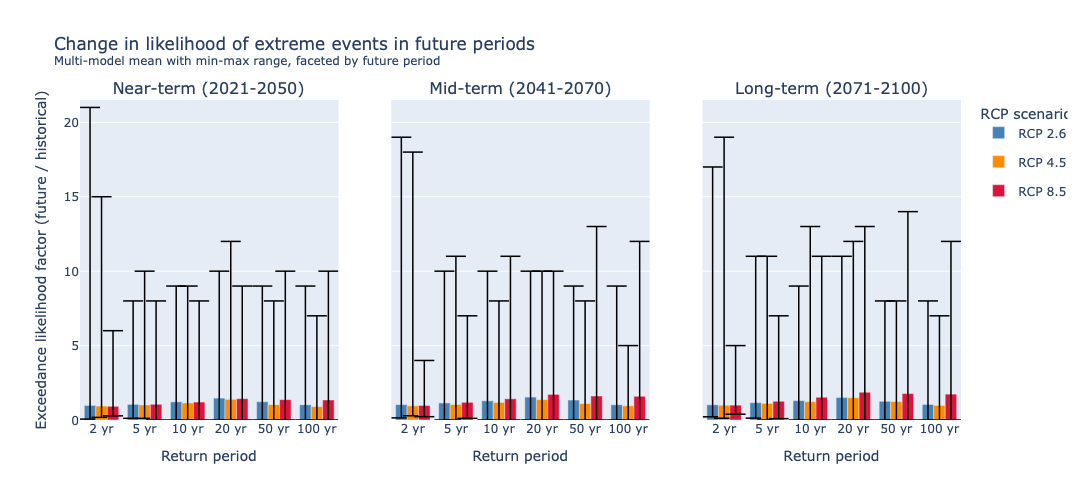

In [14]:

# plot barplot of the multi-model mean factor for each return period and future period, with error bars showing the min-max range across the models, faceted by future period
summary_future = future_rp_df.groupby(['rcp', 'period', 'return_period'])['factor'].agg(['mean', 'min', 'max']).reset_index()
summary_future = summary_future.rename(columns={'mean': 'avg_factor', 'min': 'min_factor', 'max': 'max_factor'})
print("\nSummary of exceedance likelihood factors across models for each return period and future period:")
print(summary_future)

future_period_names = list(future_periods.keys())
ymax = summary_future['max_factor'].max() + 0.5

fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=future_period_names,
    shared_yaxes=True,
    horizontal_spacing=0.06,
)

for col_idx, period_name in enumerate(future_period_names, start=1):
    period_data = summary_future[summary_future['period'] == period_name]
    for rcp in rcps:
        rcp_data = period_data[period_data['rcp'] == rcp]
        fig.add_trace(go.Bar(
            x=rcp_data['return_period'].astype(str) + ' yr',
            y=rcp_data['avg_factor'],
            name=rcp_labels.get(rcp, rcp),
            marker_color=rcp_colors.get(rcp, 'grey'),
            legendgroup=rcp,
            showlegend=(col_idx == 1),
            error_y=dict(
                type='data',
                symmetric=False,
                array=rcp_data['max_factor'] - rcp_data['avg_factor'],
                arrayminus=rcp_data['avg_factor'] - rcp_data['min_factor'],
                thickness=1.5,
                width=10,
                color='black',
            ),
        ), row=1, col=col_idx)

fig.update_yaxes(
    title_text='Exceedance likelihood factor (future / historical)',
    range=[0, ymax],
    row=1, col=1,
)
fig.update_xaxes(title_text='Return period')
fig.update_layout(
    title='Change in likelihood of extreme events in future periods <br><sup>Multi-model mean with min-max range, faceted by future period</sup>',
    legend_title='RCP scenario',
    barmode='group',
    autosize=True,
    height=500,
)
fig.show(config={'displayModeBar': True, 'responsive': True})


### Local changes

The following plots focus on the sample grid point and show how the return period and event likelihood change from the historical baseline to each future time horizon, for all three RCP scenarios and all ensemble members.


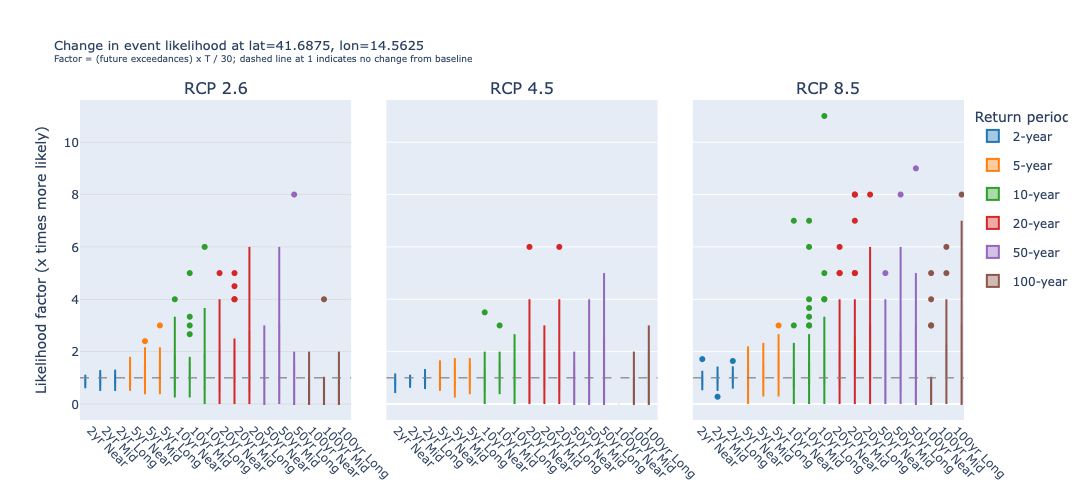

In [15]:

# -- Plot B: "x times more likely" boxplot at the sample grid point --
# X-axis: grouped by return period (6) then future period (3) = 18 boxes per RCP panel
# Y-axis: likelihood factor = n_exceed * T / 30
# Color:  return period category
# Panels: one per RCP scenario (3 columns)

# Subset future_rp_df to the sample grid point
sample_fp = future_rp_df[
    (future_rp_df['lat'] == sample_lat) &
    (future_rp_df['lon'] == sample_lon)
]

rp_all     = [2, 5, 10, 20, 50, 100]
rp_all_hex = {
    2:   '#1f77b4',
    5:   '#ff7f0e',
    10:  '#2ca02c',
    20:  '#d62728',
    50:  '#9467bd',
    100: '#8c564b',
}
period_abbrev = {
    'Near-term (2021-2050)': 'Near',
    'Mid-term (2041-2070)':  'Mid',
    'Long-term (2071-2100)': 'Long',
}

fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=[rcp_labels[r] for r in rcps],
    shared_yaxes=True,
    horizontal_spacing=0.04,
)

for col_idx, rcp in enumerate(rcps, start=1):
    rcp_data = sample_fp[sample_fp['rcp'] == rcp]

    for rp_val in rp_all:
        rp_data_rp = rcp_data[rcp_data['return_period'] == rp_val]
        show_leg   = (col_idx == 1)

        for period_name in future_period_names:
            period_data = rp_data_rp[rp_data_rp['period'] == period_name]
            x_label     = f'{rp_val}yr {period_abbrev[period_name]}'

            fig.add_trace(go.Box(
                y=period_data['factor'],
                x=[x_label] * len(period_data),
                name=f'{rp_val}-year' if show_leg and period_name == future_period_names[0] else None,
                legendgroup=str(rp_val),
                showlegend=show_leg and period_name == future_period_names[0],
                marker_color=rp_all_hex[rp_val],
                line_color=rp_all_hex[rp_val],
                fillcolor=f"rgba({','.join(str(int(rp_all_hex[rp_val].lstrip('#')[i:i+2],16)) for i in (0,2,4))},0.4)",
                boxmean=True,
                hovertemplate=(
                    f'{rp_val}-yr {period_abbrev[period_name]}<br>'
                    'Factor: %{y:.2f}<extra></extra>'
                ),
            ), row=1, col=col_idx)

    # Reference line at factor = 1 (no change)
    fig.add_hline(y=1, line_dash='dash', line_color='grey', line_width=1.2,
                  row=1, col=col_idx)

    fig.update_xaxes(
        tickangle=45,
        showgrid=False,
        row=1, col=col_idx,
    )

fig.update_yaxes(
    title_text='Likelihood factor (x times more likely)',
    showgrid=True, gridcolor='lightgrey', gridwidth=0.5,
    zeroline=False,
    row=1, col=1,
)
fig.update_layout(
    title=dict(
        text=(
            f'Change in event likelihood at lat={sample_lat}, lon={sample_lon}<br>'
            f'<sup>Factor = (future exceedances) x T / 30; '
            f'dashed line at 1 indicates no change from baseline</sup>'
        ),
        font=dict(size=13),
    ),
    boxmode='group',
    legend=dict(title='Return period', x=1.01, y=0.99, xanchor='left', yanchor='top'),
    autosize=True,
    height=500,
)
fig.show(config={'displayModeBar': True, 'responsive': True})


### Regional changes

The maps below show the spatial distribution of the likelihood change factor for the 50-year return period event across all three future periods, using one ensemble member and the high-emission scenario (RCP 8.5). A factor greater than 1 (red shades) indicates that the event has become more frequent; a factor less than 1 (blue shades) indicates a decrease in frequency.


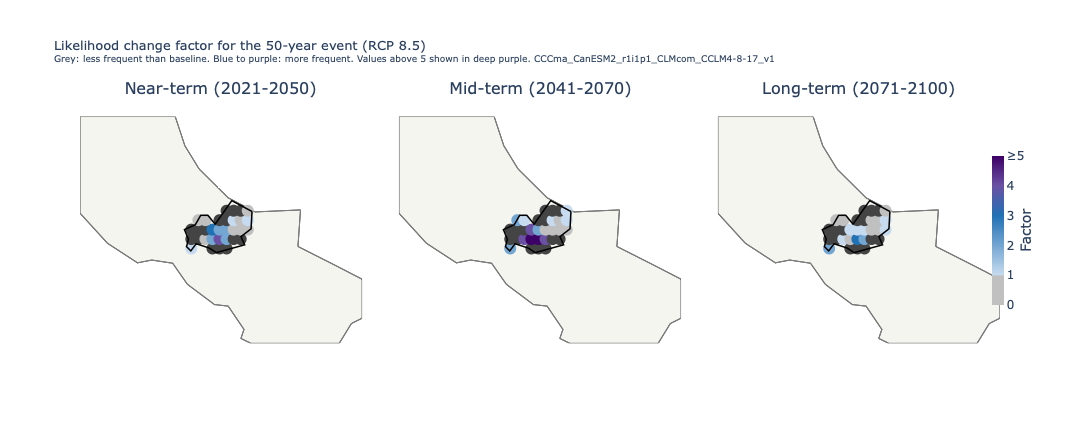

In [16]:
# 1x3 maps of the "x times more likely" factor
# Settings: 50-year RP, RCP 8.5, one example model
rp_map    = 50
rcp_map   = 'rcp_8_5'
model_map = example_model

map_data = future_rp_df[
    (future_rp_df['return_period'] == rp_map) &
    (future_rp_df['rcp']           == rcp_map) &
    (future_rp_df['member_id']     == model_map)
].copy()

# Fixed colour scale: 0 to 5 (values > 5 shown in deep purple)
# factor = 1 sits at normalised position 1/5 = 0.20
cmin_map   = 0.0
cmax_map   = 5.0
factor_one = 1.0 / cmax_map  # = 0.20

# Grey for factor <= 1; blue -> purple for factor > 1
custom_cscale = [
    [0.0,                '#c0c0c0'],  # grey at factor = 0
    [factor_one - 0.001, '#c0c0c0'],  # grey just below factor = 1 (hard edge)
    [factor_one,         '#c6dbef'],  # light blue at factor = 1
    [0.60,               '#2171b5'],  # blue at factor ~ 3
    [0.80,               '#6a51a3'],  # blue-purple at factor ~ 4
    [1.00,               '#3d0066'],  # deep purple at factor >= 5
]

fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=future_period_names,
    specs=[[{'type': 'geo'}, {'type': 'geo'}, {'type': 'geo'}]],
    horizontal_spacing=0.04,
)

for col_idx, period_name in enumerate(future_period_names, start=1):
    period_data = map_data[map_data['period'] == period_name]
    geo_key     = 'geo' if col_idx == 1 else f'geo{col_idx}'

    fig.add_trace(
        go.Scattergeo(
            lat=period_data['lat'],
            lon=period_data['lon'],
            mode='markers',
            name=period_name,
            showlegend=False,
            marker=dict(
                color=period_data['factor'],
                colorscale=custom_cscale,
                size=12,
                cmin=cmin_map,
                cmax=cmax_map,
                showscale=(col_idx == 3),
                colorbar=dict(
                    title=dict(text='Factor', side='right'),
                    thickness=12,
                    tickvals=[0, 1, 2, 3, 4, 5],
                    ticktext=['0', '1', '2', '3', '4', '\u22655'],
                    x=0.98,
                    len=0.65,
                    lenmode='fraction',
                    thicknessmode='pixels',
                ),
            ),
            hovertemplate=(
                'lat: %{lat:.4f}, lon: %{lon:.4f}<br>'
                'Factor: %{marker.color:.2f}<extra></extra>'
            ),
            geo=geo_key,
        ),
        row=1, col=col_idx,
    )
    fig.add_trace(region_boundary_trace(geo_key=geo_key), row=1, col=col_idx)
    fig.update_layout(**{geo_key: geo_settings})

fig.update_layout(
    title=dict(
        text=(
            f'Likelihood change factor for the {rp_map}-year event '
            f'({rcp_labels[rcp_map]})<br>'
            f'<sup>Grey: less frequent than baseline. Blue to purple: more frequent. '
            f'Values above 5 shown in deep purple. {model_map}</sup>'
        ),
        font=dict(size=13),
    ),
    autosize=True,
    height=440,
)
fig.show(config={'displayModeBar': True, 'responsive': True})


The maps confirm that the projected increase in extreme-event likelihood is a **spatially coherent signal** across the Molise region — not an artefact of a single location or model. The signal strengthens progressively from the near-term to the long-term period and from low to high emission scenarios. Together with the model-spread visible in the earlier boxplots, this underlines both the robustness of the projected direction of change and the remaining uncertainty in its precise magnitude.

## Summary

### How future changes in extreme precipitation are assessed

In this tutorial, we estimated how the frequency of historically rare precipitation events may change under future climate projections. The analysis proceeds in four steps:

1. **Establish a historical baseline.** Fit a GEV distribution to annual maxima at each model–grid-point combination over the reference period (1976–2005) to derive T-year return levels.
2. **Use return levels as fixed thresholds.** Rather than refitting the GEV for each future period, the historical return levels serve as event thresholds — allowing a direct comparison between periods.
3. **Count future exceedances.** For each 30-year future window and each RCP scenario, count how many times each threshold is exceeded and compute the likelihood change factor (future count / historical count).
4. **Summarise across models and space.** Report the multi-model mean and spread to quantify uncertainty; map the spatial pattern of change to assess regional coherence.

A likelihood change factor greater than 1 means the event has become more frequent; a factor of 2 means it is twice as likely in the future as in the historical baseline.

### Key findings for Molise (ITF2)

- **All three RCP scenarios project an increase** in the frequency of extreme precipitation events. The magnitude of the increase grows with emission level (RCP 2.6 < RCP 4.5 < RCP 8.5) and with time horizon (near-term < mid-term < long-term).
- **Rarer events (longer return periods) show larger absolute changes** in likelihood. A historically 50- or 100-year event is projected to recur considerably more often by end-of-century under high emissions.
- **The signal is spatially coherent** across the region — the increase in likelihood is not confined to a single grid point but covers most of Molise, increasing confidence that the projection reflects a genuine climatic shift.
- **Model uncertainty is substantial**, particularly for rare events and long time horizons. The spread across ensemble members is large enough that individual model results should never be used in isolation.

### Sources of uncertainty

**(i) GEV fit quality**  
The analysis assumes annual maxima follow a GEV distribution. Where this assumption is violated (e.g. due to non-stationarity), the derived thresholds and resulting factors may be biased.

**(ii) Fixed historical thresholds**  
The likelihood factor is computed against a fixed historical return level. If the distribution of annual maxima shifts (not just its tail), this approach captures frequency change but not the full picture of intensity change.

**(iii) Model uncertainty**  
Different regional climate models can disagree substantially on the magnitude of change. The min–max range across ensemble members shown in the plots reflects this structural uncertainty.

**(iv) Scenario uncertainty**  
Future greenhouse gas concentrations are not known. The three RCP scenarios (2.6, 4.5, 8.5) span a plausible range, but the realised pathway will depend on global mitigation efforts.

```{admonition} Take-aways and best practice
:class: tip

Climate projections indicate that extreme precipitation events will become more frequent in Molise under continued warming, but the precise magnitude of change is uncertain.

**Best practice recommendations:**

- **Always use the full model ensemble.** A single model can give very different results from the ensemble mean. Report the multi-model spread alongside the mean.
- **Consider multiple future periods and scenarios.** Near-term changes are relatively similar across scenarios; differences become substantial only in the mid- and long-term.
- **Pair frequency change with intensity change.** This tutorial addresses how often historical thresholds are exceeded. A complementary analysis could ask how intense future events will be (i.e. fit GEV to future periods and compare return levels directly).
- **Contextualise spatial variability.** Return levels and likelihood factors vary across the region. A single grid point or a regional mean alone can be misleading; always examine the spatial distribution.
```